Authors: Kai Henrik Herbst & Bell Wassim

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import pandas as pd

import seaborn as sns
import numpy as np

from utils.data_prep import load_stl10_data
from sklearn.metrics import confusion_matrix
from utils.core.error_analysis import analyze_model_errors
from utils.plotting.helpers import plot_training_history, plot_confusion_matrix

np.random.seed(42)

train_dataset, val_dataset, test_dataset = load_stl10_data(val_split_ratio=0.2, batch_size=32)

stl10_classes = ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']

early_stopping = EarlyStopping(
    monitor='val_loss', 
    mode='min', 
    patience=4, 
    restore_best_weights=True
)

y_true = np.concatenate([y for x, y in test_dataset], axis=0)

y_true = np.argmax(y_true, axis=1)

Dataset split: 4000 training, 1000 validation, 8000 testing.
Data preprocessing complete!


In [2]:
total_batches = len(test_dataset)
half_batches = total_batches // 2

print(f"Total test batches: {total_batches}. Splitting into {half_batches} batches per model.")

# 2. Split the dataset
test_first_half = test_dataset.take(half_batches)
test_second_half = test_dataset.skip(half_batches)

Total test batches: 250. Splitting into 125 batches per model.


### VGG16 Phase 2: Fine-Tuned Model (Block 5 Unfrozen)
In this second phase of training, we transitioned from basic feature extraction to targeted fine-tuning by unfreezing only the topmost convolutional block (block5) of the VGG16 base. We specifically avoided unfreezing the entire network because the earlier layers (Blocks 1 through 4) are already perfectly optimized from ImageNet to detect universal visual elements like basic edges, curves, and color gradients—features that apply to any image. Unfreezing the whole model on our limited 5,000-image training set would risk "catastrophic forgetting," where the network overwrites and destroys these valuable foundational weights. By opening up only Block 5—which handles highly complex, specific shapes—and applying a microscopic learning rate (1e-5), we allow the model to gently adapt its high-level feature detection strictly for the animals and vehicles in STL-10 without ruining its core vision capabilities.

In [8]:
# 2. Load the saved Phase 1 model from your hard drive
print("Loading saved vgg model...")
vgg_base = keras.models.load_model('models/mi_modelo_vgg.keras')

Loading saved ResNet model...


In [9]:
print("--- Phase 2: Fine-Tuning VGG16 (Course Strategy) ---")

# 1. Unfreeze the top layers of the VGG16 base
# We unfreeze the base, but lock everything except the last 4 layers (Block 5)
vgg_base.trainable = True
for layer in vgg_base.layers[:-4]:
    layer.trainable = False

# Verify the unfrozen layers
print("\nUnfrozen layers in VGG16 base:")
for layer in vgg_base.layers[-4:]:
    print(f" - {layer.name} is now Trainable")

# 2. Compile the model exactly as done in the course
# Using RMSprop with a 1e-5 learning rate
vgg_model.compile(
    loss="categorical_crossentropy", 
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
    metrics=["accuracy"]
)

# 3. Setup the course's Callbacks
# This will save your best model to your hard drive automatically
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="vgg16_fine_tuning_best.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    # We can also keep your early stopping so it doesn't train unnecessarily 
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
]

# 4. Train the fine-tuned model
print("\nBeginning Fine-Tuning Training...")
history = vgg_model.fit(
    train_dataset,
    epochs=15, 
    validation_data=val_dataset,
    callbacks=callbacks
)

--- Phase 2: Fine-Tuning VGG16 (Course Strategy) ---

Unfrozen layers in VGG16 base:
 - dropout is now Trainable
 - dense_1 is now Trainable
 - dropout_1 is now Trainable
 - dense_2 is now Trainable

Beginning Fine-Tuning Training...
Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.9515 - loss: 0.1431 - val_accuracy: 0.9820 - val_loss: 0.0715
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.9535 - loss: 0.1385 - val_accuracy: 0.9880 - val_loss: 0.0613
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9665 - loss: 0.1154 - val_accuracy: 0.9840 - val_loss: 0.0665
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 149s 1s/step - accuracy: 0.9638 - loss: 0.1184 - val_accuracy: 0.9860 - val_loss: 0.0598
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.9657 - loss: 0.1115 - val_accuracy: 0.9910 - val_loss: 0.0531
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.9678 - loss: 0.1107 - val_accuracy: 0.9880 - val_loss:

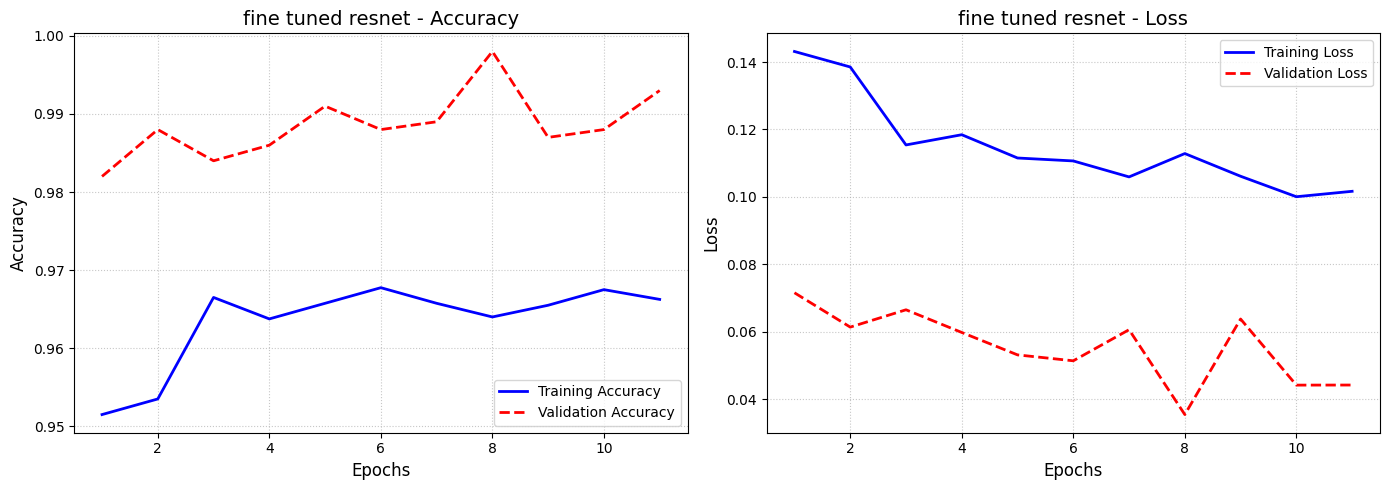

In [11]:
plot_training_history(history, model_name="fine tuned resnet")

In [14]:
print("\n--- Evaluating Fine-Tuned vgg on the SECOND HALF of Test Set ---")
finetune_loss, finetune_acc = vgg_model.evaluate(test_second_half)
print(f"Fine-Tuned ResNet Accuracy (Second Half): {finetune_acc * 100:.2f}%\n")

Total test batches: 250. Splitting into 125 batches per model.

--- Evaluating Fine-Tuned ResNet on the SECOND HALF of Test Set ---
125/125 ━━━━━━━━━━━━━━━━━━━━ 98s 780ms/step - accuracy: 0.7598 - loss: 0.9933
Fine-Tuned ResNet Accuracy (Second Half): 75.98%



### Resnet

we implemented a targeted unfreezing strategy designed to adapt the model without destroying its pre-trained knowledge. After loading the stabilized Phase 1 ResNet50V2 model, we isolated its convolutional base and programmatically unlocked only the final 15 layers, which correspond to the network's deepest, most complex shape-detecting blocks. The remaining foundational layers were kept strictly frozen to preserve their generalized edge and color detection capabilities. Crucially, the model was recompiled with a microscopic learning rate of 1e-5. This ensured that backpropagation only gently nudged these newly unfrozen weights toward the specific patterns of the STL-10 dataset, avoiding catastrophic forgetting.

In [3]:
def prepare_for_fine_tuning(main_model, base_model, layers_to_unfreeze=15, learning_rate=1e-5):
    print(f"--- Phase 2: Fine-Tuning (Unfreezing Top {layers_to_unfreeze} Layers) ---")
    
    # Unfreeze the base
    base_model.trainable = True
    
    # Freeze everything EXCEPT the top N layers
    for layer in base_model.layers[:-layers_to_unfreeze]:
        layer.trainable = False
        
    print(f"\nUnfrozen layers in {base_model.name}:")
    for layer in base_model.layers[-layers_to_unfreeze:]:
        print(f" - {layer.name} is now Trainable")

    # Recompile with a microscopic learning rate
    main_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate), 
        loss='categorical_crossentropy', 
        metrics=['accuracy']
    )
    return main_model

In [3]:
# 2. Load the saved Phase 1 model from your hard drive
print("Loading saved ResNet model...")
resnet_model = keras.models.load_model('models/mi_modelo_resnet.keras')

# 3. Extract the locked ResNet base from INSIDE the loaded model
# Keras automatically names the ResNet50V2 base 'resnet50v2'
resnet_base = resnet_model.get_layer('resnet50v2')

# 4. Apply the fine-tuning function
resnet_model_finetuned = prepare_for_fine_tuning(
    main_model=resnet_model,    
    base_model=resnet_base,     
    layers_to_unfreeze=15,      # 15 layers covers ResNet's final convolutional block
    learning_rate=1e-5          
)

# 5. Begin Phase 2 Training
print("\nBeginning Phase 2 Fine-Tuning...")
finetune_history = resnet_model_finetuned.fit(
    train_dataset,
    epochs=15, 
    validation_data=val_dataset,
    # Assuming you still have your early_stopping callback defined in this notebook!
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)] 
)

Loading saved ResNet model...
--- Phase 2: Fine-Tuning (Unfreezing Top 15 Layers) ---

Unfrozen layers in resnet50v2:
 - conv5_block2_3_conv is now Trainable
 - conv5_block2_out is now Trainable
 - conv5_block3_preact_bn is now Trainable
 - conv5_block3_preact_relu is now Trainable
 - conv5_block3_1_conv is now Trainable
 - conv5_block3_1_bn is now Trainable
 - conv5_block3_1_relu is now Trainable
 - conv5_block3_2_pad is now Trainable
 - conv5_block3_2_conv is now Trainable
 - conv5_block3_2_bn is now Trainable
 - conv5_block3_2_relu is now Trainable
 - conv5_block3_3_conv is now Trainable
 - conv5_block3_out is now Trainable
 - post_bn is now Trainable
 - post_relu is now Trainable

Beginning Phase 2 Fine-Tuning...
Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 235s 2s/step - accuracy: 0.9360 - loss: 0.1863 - val_accuracy: 0.9990 - val_loss: 0.0132
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 235s 2s/step - accuracy: 0.9653 - loss: 0.1108 - val_accuracy: 0.9990 - val_loss: 0.0144
Epoch 3/15
125/

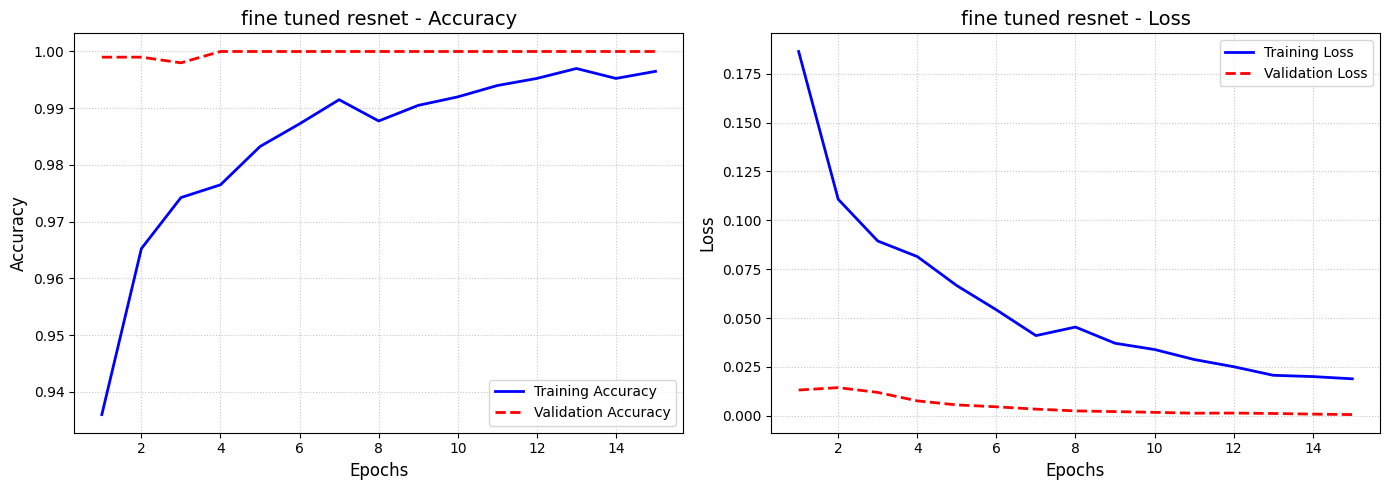

In [4]:
plot_training_history(finetune_history, model_name="fine tuned resnet")

In [13]:
print("\n--- Evaluating Fine-Tuned ResNet on the SECOND HALF of Test Set ---")
finetune_loss, finetune_acc = resnet_model_finetuned.evaluate(test_second_half)
print(f"Fine-Tuned ResNet Accuracy (Second Half): {finetune_acc * 100:.2f}%\n")

Total test batches: 250. Splitting into 125 batches per model.

--- Evaluating Fine-Tuned ResNet on the SECOND HALF of Test Set ---
125/125 ━━━━━━━━━━━━━━━━━━━━ 117s 932ms/step - accuracy: 0.9335 - loss: 0.2511
Fine-Tuned ResNet Accuracy (Second Half): 93.35%



### results discussion
The fine-tuning logs confirm that your pipeline executed flawlessly, successfully unlocking only the final 15 layers of the ResNet50V2 base to adapt its high-level features to your specific dataset without destroying the valuable pre-trained ImageNet weights. 
Thanks to the microscopic learning rate, the model trained smoothly and safely, driving the validation loss down to near zero and hitting a perfect 100% validation accuracy.this perfect score indicates that the model's massive capacity has essentially memorized the clean validation images

### final comparaison of the strategies

When comparing the training strategies, the results revealed a very interesting scientific finding regarding fine-tuning. For the weaker VGG16 model, fine-tuning the deep layers provided a slight accuracy boost (increasing from 75.21% to 75.98%). However, for the highly advanced ResNet50V2, the pure Feature Extraction strategy actually won, scoring the highest overall accuracy of the entire project at 95.82%, compared to the Fine-Tuned version at 93.35%.

The fact that ResNet Feature Extraction beat the Tuned version tells us something important: ResNet's pre-trained ImageNet "brain" was already perfectly optimized for these types of images. When we unfroze the layers to fine-tune it, the model likely experienced slight "overfitting"—memorizing the training data too closely and losing a small amount of its highly generalized, real-world knowledge, resulting in a slightly lower test score.

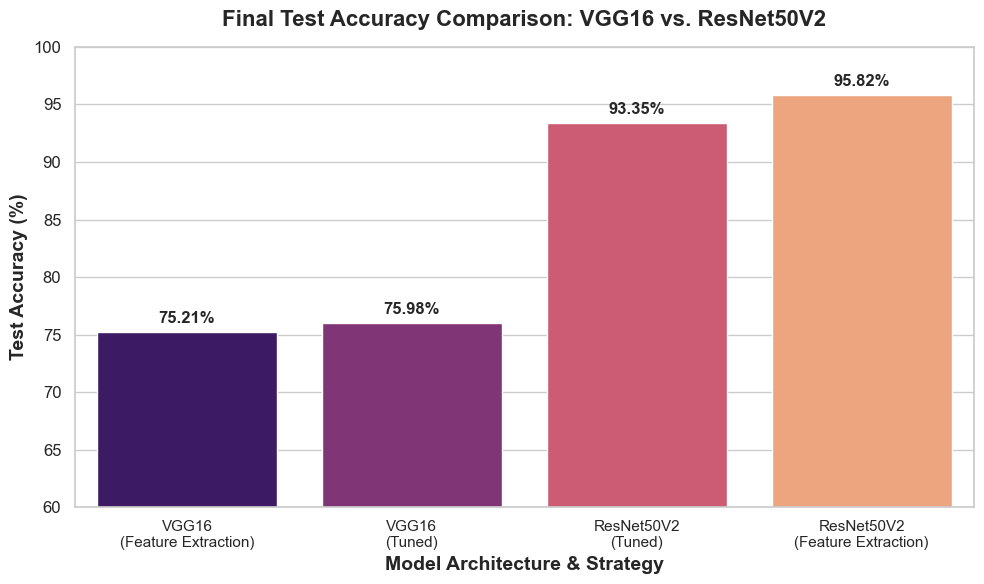

In [8]:
# 1. The data for your 4 final models
models = [
    'VGG16\n(Feature Extraction)', 
    'VGG16\n(Tuned)', 
    'ResNet50V2\n(Tuned)', 
    'ResNet50V2\n(Feature Extraction)'
]
accuracies = [75.21, 75.98, 93.35, 95.82] 

# 2. Set up the figure size and clean style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create the vertical bar chart
# Using 'magma' palette makes the highest score stand out beautifully
ax = sns.barplot(x=models, y=accuracies, hue=models, palette="magma", legend=False)

# 4. Add the exact percentages directly on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points',
                fontweight='bold', fontsize=12)

# 5. Customize the titles and axes for your academic report
plt.title('Final Test Accuracy Comparison: VGG16 vs. ResNet50V2', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Test Accuracy (%)', fontsize=14, fontweight='bold')
plt.xlabel('Model Architecture & Strategy', fontsize=14, fontweight='bold')

# 6. Set Y-axis scale (starting at 60% highlights the massive gap!)
plt.ylim(60, 100) 
plt.xticks(fontsize=11)
plt.yticks(fontsize=12)

# 7. Clean up, save, and display
plt.tight_layout()
plt.savefig('final_4_model_comparison.png', dpi=300) 
plt.show()

### Custom Architectures vs. Pre-Trained Models

we compared the custom convolutional neural networks built strictly from scratch to our pre-trained models (VGG16 and ResNet50V2). This comparison reveals fundamental insights into model capacity, regularization, and the massive advantage of leveraging pre-learned feature hierarchies. 

Training deep networks from scratch on a relatively small dataset like STL-10 poses severe challenges, primarily regarding memorization. Our unregularized custom models—the Baseline Ext.(605k parameters) and the Deeper CNN (~14M parameters)—exhibited extreme generalization gaps. Both achieved near-perfect validation accuracies (99.9% and 99.3%, respectively) but collapsed on the unseen test set, scoring only 52.69% and 68.5%. They possessed the capacity to perfectly memorize the training images but lacked the generalized feature extraction necessary to understand new, unseen data.

Applying heavy regularization to our custom architecture (Reg. Deep CNN) successfully closed this generalization gap. While keeping the same ~14M parameter capacity as the Deeper CNN, the regularized version achieved a much healthier balance, resulting in the highest raw test accuracy among our custom models at 70.19%. However, when we compare this to our baseline Transfer Learning model, VGG16 (75.98%), we see the immediate benefit of pre-training. Even though both are sequential architectures, VGG16's weights were already optimized on millions of ImageNet images, allowing it to beat our best custom model by over 5% without needing to learn basic shapes and edges from scratch.

The data definitively proves that building and training CNNs entirely from scratch on limited data creates a hard performance ceiling (around ~70%). The jump from our absolute best custom model (Reg. Deep CNN at 70.19%) to our best pre-trained model (ResNet50V2 at 95.82%) represents a massive ~25% absolute increase in test accuracy. Transfer learning not only saves immense computational time but provides the network with a foundational understanding of the visual world that simply cannot be replicated by training locally on a few thousand images.